# What makes a book loved by readers?

This notebook walks through the analysis of **goodbooks-10k**: the 10,000 most
popular books on Goodreads, with about 6 million ratings by 53,424 users and the
tags (shelves) that readers gave to the books.

We look at the factors that may go together with how much a book is
**appreciated** (its average rating, from 1 to 5 stars):

1. How are the ratings distributed?
2. Are some **genres** consistently rated higher?
3. Are **older books** rated differently from recent ones?
4. Are **popular** books (many ratings) also the most appreciated?
5. How do the ratings of an **author** evolve across their works?
6. How do the individual **readers** rate?

All the logic lives in the `goodbooks` package (`data.py`, `genres.py`,
`analysis.py`, `plots.py`): this notebook only calls its functions and shows the
results.

## Setup

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import os
import sys

# Jupyter runs the notebook from its folder (notebooks/),
# so the root of the project is its parent
PROJECT_ROOT = os.path.dirname(os.getcwd())

# Let Python find the goodbooks package, which lives in the root of the project
if PROJECT_ROOT not in sys.path:
    sys.path.append(PROJECT_ROOT)

In [3]:
import requests
import seaborn as sns

from goodbooks import analysis, data, plots

sns.set_theme(style="whitegrid")

## Loading the data

`download_dataset` downloads the CSV files from the GitHub repository of
goodbooks-10k into `data/`, only if they are not there yet (`ratings.csv` is 72 MB).
If the download fails, we show the error instead of going on without data.

In [4]:
try:
    data.download_dataset()
except requests.exceptions.RequestException as error:
    print(f"Could not download the dataset: {error}")
    print("Download the CSV files by hand into the data/ folder (see the README).")

`load_books` reads `books.csv`, `book_tags.csv` and `tags.csv`, and cleans them:

- it keeps the useful columns, turns the publication year into an integer and
  groups the years into **eras** (`pd.cut`);
- it takes the **main author** (the first one of the list) and removes the series
  from the titles (e.g. *"(The Hunger Games, #1)"*);
- it marks the **box sets and collections**, which are not new works;
- it computes the **standard deviation of the stars** of each book with NumPy, from
  the number of 1, 2, 3, 4 and 5 star ratings: how *divisive* the book is;
- it gives each book a **genre**, the one whose tags were used most by its readers
  (see `genres.py`);
- it adds a **weighted rating** (see question 4).

In [5]:
books = data.load_books()
print(f"{len(books):,} books, {books['main_author'].nunique():,} authors")
books[["short_title", "main_author", "year", "era", "genre", "average_rating", "ratings_count"]].head()

10,000 books, 3,888 authors


,short_title,main_author,year,era,genre,average_rating,ratings_count
0,The Hunger Games,Suzanne Collins,2008,2000-2009,Young Adult,4.34,4780653
1,Harry Potter and the Sorcerer's Stone,J.K. Rowling,1997,1950-1999,Fantasy,4.44,4602479
2,Twilight,Stephenie Meyer,2005,2000-2009,Young Adult,3.57,3866839
3,To Kill a Mockingbird,Harper Lee,1960,1950-1999,Classics,4.25,3198671
4,The Great Gatsby,F. Scott Fitzgerald,1925,1900-1949,Classics,3.89,2683664


In [6]:
# The missing values that are left: a few books have no publication year
books.isna().sum()[lambda counts: counts > 0]

year    21
era     21
dtype: int64

## 1. How are the ratings distributed?

In [7]:
books["average_rating"].describe().round(2)

count    10000.00
mean         4.00
std          0.25
min          2.47
25%          3.85
50%          4.02
75%          4.18
max          4.82
Name: average_rating, dtype: float64

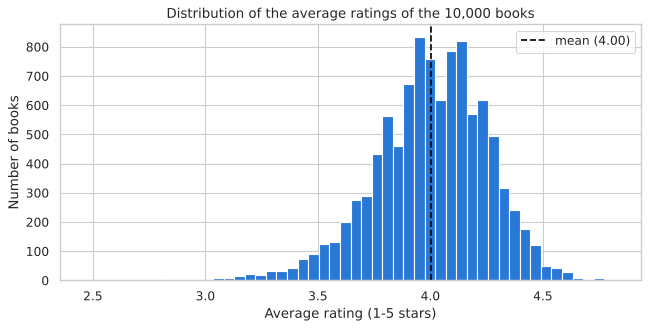

In [8]:
fig = plots.rating_histogram(books)
path = plots.save_figure(fig, "rating_histogram", data.RESULTS_DIR)

Average ratings are concentrated: half of the books are between 3.85 and 4.18
stars, and very few go below 3.5. The distribution has a longer tail on the left
(skewness about −0.5): a few books are clearly disliked, but none is loved by all.

How **divisive** is a book? The standard deviation of its stars is low when all
readers agree, high when some love it and others hate it.

In [9]:
analysis.correlation(books["star_std"], books["average_rating"])

{'rho': np.float64(-0.6448467259582129), 'p_value': np.float64(0.0), 'n': 10000}

The Spearman correlation is strongly negative (about −0.64): the best-loved books
are also the ones readers agree on, while the low averages come from
divisive books.

## 2. Are some genres consistently rated higher?

For each genre: the number of books, the mean and the median rating, and a 95%
confidence interval of the mean (mean ± 1.96 standard errors). Each genre is also
compared with all the other books with the **Mann-Whitney U test**, which doesn't
assume normal data.

In [10]:
genre_table = analysis.group_statistics(books, "genre")
genre_table = genre_table.merge(analysis.compare_with_rest(books, "genre"), on="genre")
genre_table = genre_table.sort_values("mean", ascending=False)
data.save_table(genre_table.round(4), "genre_statistics")
genre_table.round(3)

,genre,n_books,mean,median,std,ci_low,ci_high,difference,p_value
2,Comics & Manga,387,4.227,4.230,0.213,4.206,4.249,0.234,0.000
9,Poetry,61,4.169,4.220,0.235,4.110,4.228,0.168,0.000
10,Religion,192,4.146,4.175,0.249,4.111,4.181,0.147,0.000
0,Children's,538,4.141,4.160,0.171,4.127,4.155,0.147,0.000
3,Fantasy,1296,4.102,4.120,0.239,4.089,4.115,0.115,0.000
8,Non-fiction,1491,4.002,4.020,0.221,3.991,4.013,-0.000,0.466
11,Romance,1112,3.986,4.040,0.284,3.969,4.003,-0.018,0.935
13,Young Adult,1052,3.979,3.980,0.234,3.965,3.993,-0.026,0.000
12,Science Fiction,464,3.974,3.985,0.227,3.954,3.995,-0.029,0.005
4,Historical Fiction,680,3.956,3.975,0.263,3.937,3.976,-0.049,0.000


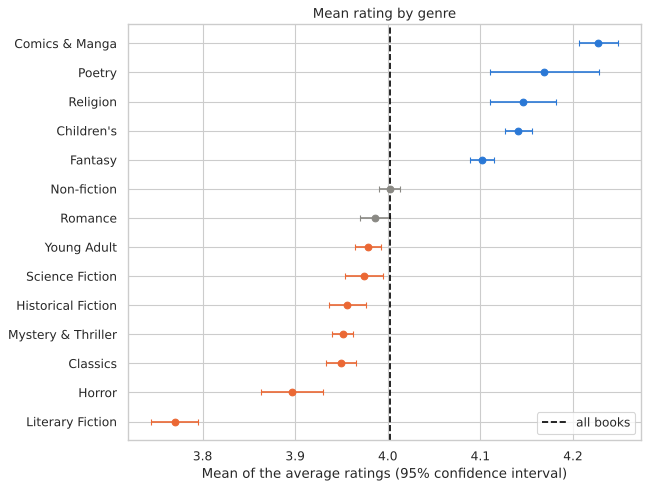

In [11]:
fig = plots.genre_means(genre_table, books["average_rating"].mean())
path = plots.save_figure(fig, "genre_means", data.RESULTS_DIR)

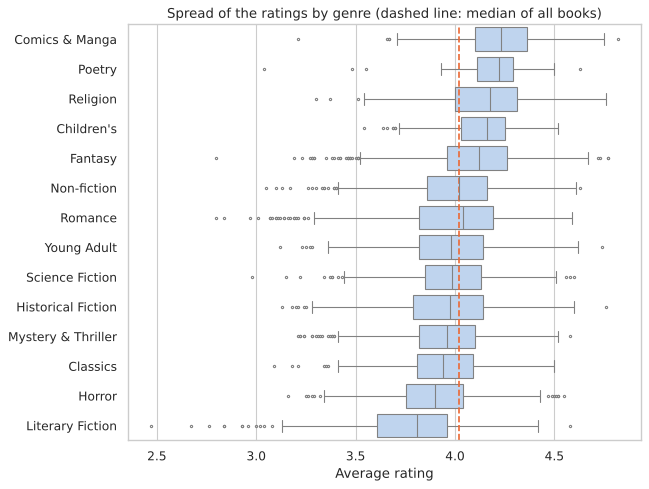

In [12]:
fig = plots.genre_boxplot(books, list(genre_table["genre"]))
path = plots.save_figure(fig, "genre_boxplot", data.RESULTS_DIR)

Yes: **comics & manga, poetry, religion, children's books and fantasy** are rated
higher than the rest, with confidence intervals well above the mean of all books
and p-values close to 0. **Literary fiction** and **horror** are at the bottom.

The box plots show that the difference is *consistent*: for comics and children's
books, most of the box lies to the right of the median of all books. A likely
reason is self-selection: these genres are read by dedicated fans, while literary
fiction reaches a broader (and more critical) audience.

## 3. Are older books rated differently from recent ones?

In [13]:
era_table = analysis.group_statistics(books, "era", min_size=10)
era_table.round(3)

,era,n_books,mean,median,std,ci_low,ci_high
0,Before 1900,379,3.941,3.94,0.224,3.918,3.964
1,1900-1949,466,4.033,4.06,0.216,4.013,4.053
2,1950-1999,2946,4.034,4.05,0.221,4.026,4.042
3,2000-2009,3121,3.977,3.99,0.265,3.968,3.987
4,2010-2017,3067,3.999,4.02,0.277,3.989,4.008


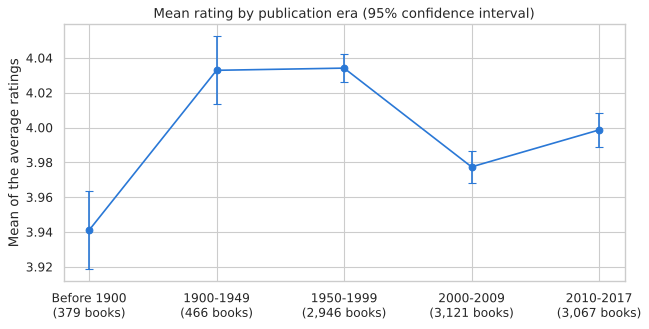

In [14]:
fig = plots.era_means(era_table)
path = plots.save_figure(fig, "era_means", data.RESULTS_DIR)

Slope: -0.008 stars per decade
R squared: 0.0039, p-value: 1e-09, 9,600 books


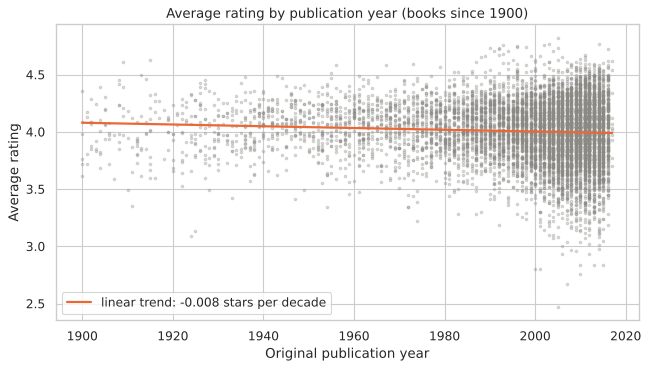

In [15]:
trend = analysis.year_trend(books, start_year=1900)
print(f"Slope: {trend['slope'] * 10:+.3f} stars per decade")
print(f"R squared: {trend['r_squared']:.4f}, p-value: {trend['p_value']:.2g}, {trend['n']:,} books")
fig = plots.year_scatter(books, trend)

The differences are small. Books published **before 1900** are rated a bit lower
(3.94), the books of the 20th century a bit higher (4.03), and the recent ones are
in between. Since 1900 the linear trend is almost flat (less than 0.01 stars per
decade, R² below 0.01): the year explains almost nothing of the rating.

Note a **survivorship bias**: the old books in the dataset are the ones still read
today (classics), often as assigned reading at school, which brings in readers who
didn't choose them.

## 4. Are popular books also the most appreciated?

Popularity is the number of ratings, which goes from a few thousands to millions:
we use its logarithm.

{'rho': np.float64(0.07919552687512278), 'p_value': np.float64(2.1735089460975705e-15), 'n': 10000}

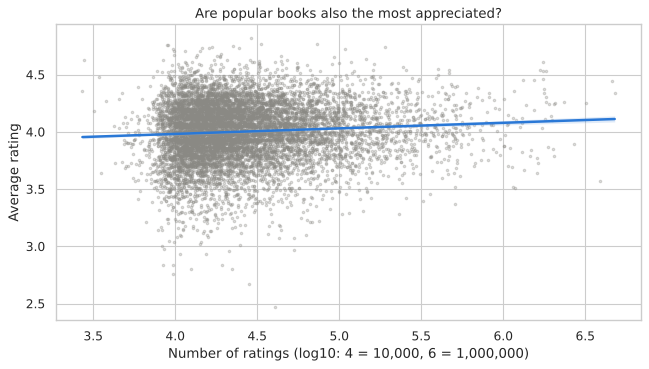

In [16]:
fig = plots.popularity_scatter(books)
path = plots.save_figure(fig, "popularity_scatter", data.RESULTS_DIR)
analysis.correlation(books["log_ratings_count"], books["average_rating"])

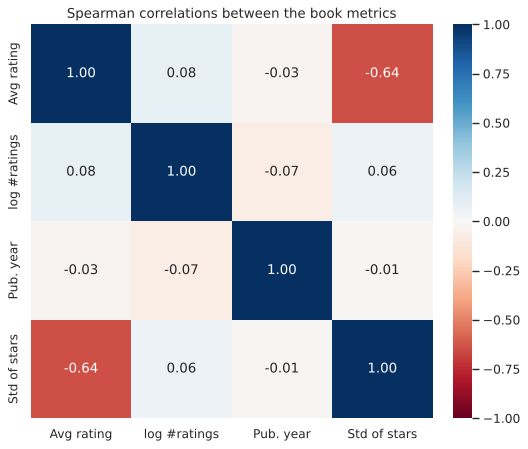

In [17]:
columns = {
    "average_rating": "Avg rating",
    "log_ratings_count": "log #ratings",
    "year": "Pub. year",
    "star_std": "Std of stars",
}
fig = plots.correlation_heatmap(books, columns)

Popularity and appreciation are almost unrelated: the Spearman correlation is only
0.08. It is "significant" (p-value close to 0) because we have 10,000 books, but
it is very weak. Being read a lot doesn't mean being loved.

Because of this, the plain average favours books with few ratings. The **weighted
rating** `WR = v/(v+m)·R + m/(v+m)·C` pulls the average `R` of each book toward
the mean of all books `C`, less and less as its number of ratings `v` grows
(`m` is the median number of ratings). These are the best-loved books by weighted
rating, without box sets and collections:

In [18]:
top_books = books[~books["is_compilation"]].nlargest(15, "weighted_rating")
top_books = top_books[["short_title", "main_author", "year", "genre", "average_rating", "ratings_count", "weighted_rating"]]
data.save_table(top_books.round(3), "top_books")
top_books.round(3)

,short_title,main_author,year,genre,average_rating,ratings_count,weighted_rating
1307,A Court of Mist and Fury,Sarah J. Maas,2016,Fantasy,4.72,108384,4.603
24,Harry Potter and the Deathly Hallows,J.K. Rowling,2007,Fantasy,4.61,1746574,4.603
861,Words of Radiance,Brandon Sanderson,2014,Fantasy,4.77,73572,4.599
561,The Way of Kings,Brandon Sanderson,2010,Fantasy,4.64,144822,4.559
26,Harry Potter and the Half-Blood Prince,J.K. Rowling,2005,Fantasy,4.54,1678823,4.533
1009,The Essential Calvin and Hobbes: A Calvin and ...,Bill Watterson,1988,Comics & Manga,4.65,93001,4.530
306,The Wise Man's Fear,Patrick Rothfuss,2011,Fantasy,4.57,245686,4.525
17,Harry Potter and the Prisoner of Azkaban,J.K. Rowling,1999,Fantasy,4.53,1832823,4.524
23,Harry Potter and the Goblet of Fire,J.K. Rowling,2000,Fantasy,4.53,1753043,4.524
191,The Name of the Wind,Patrick Rothfuss,2007,Fantasy,4.55,400101,4.522


## 5. How do the ratings of an author evolve across their works?

We follow the authors with at least 5 dated books (without box sets), sort their
books by publication year, and fit a straight line through their ratings, book
after book, with `np.polyfit`. The slope says how much the rating changes with
each new book.

In [19]:
works = analysis.author_works(books)
slopes = analysis.author_slopes(works)
slopes.head(10).round(3)

,main_author,n_books,mean_rating,slope,total_ratings
181,J.K. Rowling,14,4.294,-0.030,15717203
428,Suzanne Collins,8,4.186,0.017,8516728
421,Stephenie Meyer,11,3.811,0.038,8413249
419,Stephen King,79,3.968,-0.002,8177370
183,J.R.R. Tolkien,8,4.216,-0.070,5363937
385,Rick Riordan,26,4.287,0.005,5220423
90,Dan Brown,7,3.794,0.026,5002760
465,William Shakespeare,24,3.863,0.003,4426093
344,Nicholas Sparks,20,4.008,-0.001,4302436
63,Cassandra Clare,17,4.291,-0.001,4281188


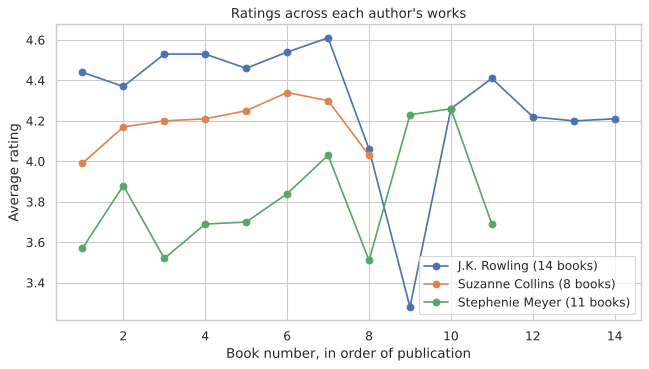

In [20]:
fig = plots.author_lines(works, ["J.K. Rowling", "Suzanne Collins", "Stephenie Meyer"])
path = plots.save_figure(fig, "author_lines", data.RESULTS_DIR)

468 authors
Median slope: +0.0006 stars per book
Authors who improve: 51%


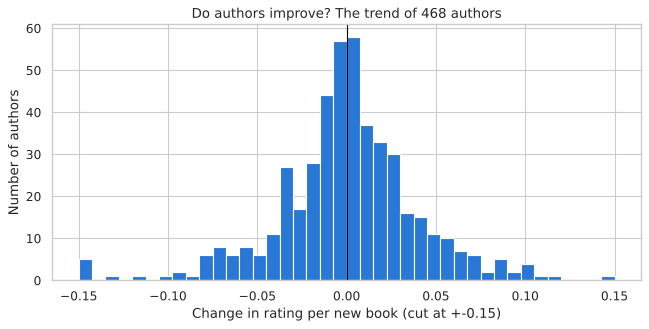

In [21]:
print(f"{len(slopes)} authors")
print(f"Median slope: {slopes['slope'].median():+.4f} stars per book")
print(f"Authors who improve: {(slopes['slope'] > 0).mean():.0%}")
fig = plots.slope_histogram(slopes)

Single authors can change a lot: J.K. Rowling's ratings fall from 4.61 (*Deathly
Hallows*) to 3.28 with *The Casual Vacancy* (2012), her first novel for adults, but **there is no general trend**: the median slope is
about 0, and about half of the authors improve while the other half decline.

## 6. How do the individual readers rate?

The 6 million individual ratings (`ratings.csv`) are loaded with small integer
types, which bring the table from about 140 MB to 40 MB in memory.

In [22]:
ratings = data.load_ratings()
users = analysis.user_summary(ratings)
print(f"{len(ratings):,} ratings by {len(users):,} users")
print(f"Median number of ratings per user: {users['n_ratings'].median():.0f}")

5,976,479 ratings by 53,424 users
Median number of ratings per user: 111


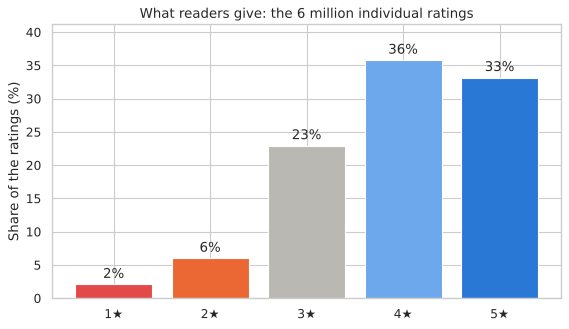

In [23]:
fig = plots.star_shares(ratings)
path = plots.save_figure(fig, "star_shares", data.RESULTS_DIR)

{'rho': np.float64(-0.09914651284335745), 'p_value': np.float64(8.792832861016409e-117), 'n': 53424}

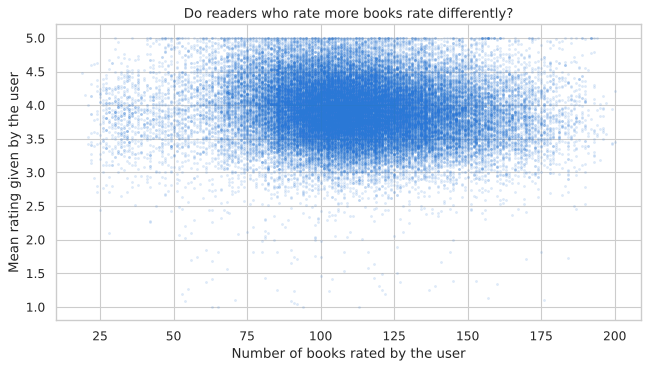

In [24]:
fig = plots.user_scatter(users)
analysis.correlation(users["n_ratings"], users["mean_rating"])

Readers are generous: about 69% of the ratings are 4 or 5 stars, and only 8% are
1 or 2 stars. People mostly rate the books they chose, and finished. Users who rate
more books give slightly lower ratings (Spearman correlation −0.10): very active
readers are a bit more demanding.

## Conclusions

- Ratings are high and concentrated (mean 4.0); the best-loved books are also the
  least divisive.
- **Genre matters most** among the factors we studied: comics, poetry, children's
  books and fantasy are consistently rated higher, literary fiction and horror lower.
- The **publication year** and the **popularity** of a book explain almost nothing
  of its rating.
- **Authors** don't get generally better or worse over their career.
- **Readers** give mostly 4 and 5 stars; the most active ones are slightly harsher.

The tables and the charts are saved in the `results/` folder.